In [2]:
!pip install pymoo matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


--- Exercício 7: Melhores Soluções de Trade-off ---
Menor Custo: R$ 133.02 mil | Tempo: 63.96 min (Robôs: 5, Vel: 1.00 m/s)
Intermediária: R$ 217.21 mil | Tempo: 33.88 min (Robôs: 6, Vel: 2.95 m/s)
Menor Tempo: R$ 527.02 mil | Tempo: 17.93 min (Robôs: 17, Vel: 3.74 m/s)


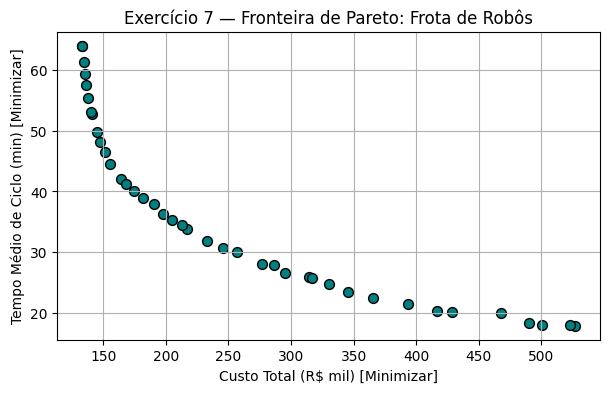

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class FrotaRobosProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([5.0, 1.0]),
            xu=np.array([50.0, 4.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):
        x1, x2 = x[0], x[1] # x1 = Número de robôs, x2 = Velocidade

        # Objetivos
        f1_custo = (x1 * 25.0) + ((x2 ** 2) * 8.0)
        f2_tempo = (120.0 / x1) + (40.0 / x2)

        # Restrição G(x) <= 0 (Consumo não pode exceder 120.0)
        consumo = x1 * (x2 ** 1.5)
        g1 = consumo - 120.0

        out["F"] = [f1_custo, f2_tempo]
        out["G"] = [g1]

# Execução do NSGA-II
res7 = minimize(FrotaRobosProblem(), NSGA2(pop_size=40), termination=('n_gen', 60), seed=7)

# Filtrar soluções da Fronteira
solucoes_ordenadas = res7.F[res7.F[:, 0].argsort()]
vars_ordenadas = res7.X[res7.F[:, 0].argsort()]

min_custo = solucoes_ordenadas[0]
min_tempo = solucoes_ordenadas[-1]
sol_intermediaria = solucoes_ordenadas[len(solucoes_ordenadas) // 2]

print("--- Exercício 7: Melhores Soluções de Trade-off ---")
print(f"Menor Custo: R$ {min_custo[0]:.2f} mil | Tempo: {min_custo[1]:.2f} min (Robôs: {vars_ordenadas[0][0]:.0f}, Vel: {vars_ordenadas[0][1]:.2f} m/s)")
print(f"Intermediária: R$ {sol_intermediaria[0]:.2f} mil | Tempo: {sol_intermediaria[1]:.2f} min (Robôs: {vars_ordenadas[len(vars_ordenadas)//2][0]:.0f}, Vel: {vars_ordenadas[len(vars_ordenadas)//2][1]:.2f} m/s)")
print(f"Menor Tempo: R$ {min_tempo[0]:.2f} mil | Tempo: {min_tempo[1]:.2f} min (Robôs: {vars_ordenadas[-1][0]:.0f}, Vel: {vars_ordenadas[-1][1]:.2f} m/s)")

# Gráfico da Fronteira de Pareto
plt.figure(figsize=(7, 4))
plt.scatter(res7.F[:, 0], res7.F[:, 1], color='teal', s=50, edgecolors='black')
plt.title("Exercício 7 — Fronteira de Pareto: Frota de Robôs")
plt.xlabel("Custo Total (R$ mil) [Minimizar]")
plt.ylabel("Tempo Médio de Ciclo (min) [Minimizar]")
plt.grid(True)
plt.savefig("pareto_robos.png") # Salva o gráfico
plt.show()